# Lokalisasi Kuadran dari CSI Multi-Node — Model Pembelajaran Mesin

**Pertanyaan:** dari empat board ESP32 di empat sudut ruangan, di kuadran mana orang berada?

Notebook ini membandingkan **model terlatih** dengan **aturan tangan** yang sudah ada
(`tools/localize_baseline.py`, akurasi 79,4%). Aturan lama memakai satu angka per board
(variance amplitudo) lalu memilih pemenang lewat `argmax`. Di sini tiap board menyumbang
20 fitur, dan model yang memutuskan bagaimana menggabungkannya.

---

## Yang diukur, dan batasnya

Router ada di **tengah** ruangan, board di keempat sudut:

```
              9 m
   38 ──────────────────── bf          38 = kiri-atas
   │                       │           bf = kanan-atas
   │                       │           d0 = kiri-bawah
   │          R            │  7 m      4b = kanan-bawah
   │       (router)        │           R  = router, di TENGAH
   │                       │
   d0 ──────────────────── 4b
```

Tiap board mengukur kanal `router -> board`. Orang mengganggu sebuah board saat
**memotong garis itu**, bukan saat berdiri dekat board-nya. Jadi yang dipulihkan adalah
**ARAH (bearing) dari router, bukan JARAK**. Berdiri di tengah jalur `router->4b` dan
berdiri tepat di board `4b` menghasilkan gangguan yang mirip.

> Ini batas metode, bukan kegagalan. Tulis apa adanya di skripsi — jangan menyiratkan
> lokalisasi koordinat (x, y).

## Data

| Folder | Isi | Dipakai untuk |
|---|---|---|
| `data/loc_baseline` | 2 menit ruangan **kosong** | Menormalkan tiap board terhadap dirinya sendiri |
| `data/loc_walk` | 8 lap jalan memutar + `markers.csv` | **Satu-satunya data berlabel**: latih + uji |
| `data/loc_static` | diam per sudut | **TIDAK DIPAKAI** — lihat di bawah |

`loc_static` sengaja tidak dipakai: penandaan waktunya tidak sesuai rencana dan tidak ada
`markers.csv`, sehingga labelnya tidak bisa dipercaya. Dulu capture itu dipakai untuk
mempelajari *polaritas* (amplitudo naik atau turun saat jalur terhalang), tetapi untuk
fitur berbasis **sebaran** polaritas tidak ambigu — kehadiran orang selalu membuat kanal
*bergerak*, jadi variance selalu naik. Tidak ada yang hilang.

## Kejujuran yang menentukan hasil

Data berlabel hanya **satu sesi berisi 8 lap**. Jendela yang berdekatan sangat
berkorelasi, jadi **pembagian train/test acak per jendela akan menggelembungkan akurasi
secara menyesatkan**. Semua evaluasi di sini dikelompokkan per **lap**
(`LeaveOneGroupOut`), dan di Bagian 7 pembagian acak dijalankan sengaja untuk
memperlihatkan seberapa besar kebocorannya.


## 0. Persiapan


In [1]:
import os
import warnings

import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

import features as F

RANDOM_STATE = 0
FIGDIR = "figures"
os.makedirs(FIGDIR, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 160,
    "savefig.bbox": "tight",
    "font.size": 9,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

# Warna tetap per board, dipakai konsisten di semua gambar supaya sudut yang
# sama selalu berwarna sama.
CCOLOR = {"4b": "#4C72B0", "bf": "#DD8452", "38": "#55A868", "d0": "#C44E52"}

print("numpy", np.__version__)


numpy 2.3.5


## 1. Ekstraksi fitur

Alurnya, dan urutannya penting:

1. **Baca `.bin`** → amplitudo per subcarrier tiap paket (~35–41 Hz per board).
2. **Jendela 500 ms**, minimal 8 paket, dan hanya jendela yang terisi di **semua** board.
   Jendela yang bolong satu board tidak bisa dipakai untuk membandingkan board — board
   yang datanya hilang akan tampak seperti board yang tidak terganggu.
3. **20 fitur per board**: statistik amplitudo (mean, std, MAD, IQR), ringkasan per 8 pita
   subcarrier, turunan waktu, dan statistik RSSI.
4. **Normalisasi baseline**: `z = (x − median_kosong) / (1,4826 × MAD_kosong)`.
   MAD dipakai, bukan std, karena baseline hanya 2 menit dan satu lonjakan interferensi
   sudah cukup untuk menggelembungkan std.
5. **Fitur konteks**: peringkat dan proporsi antar board — hanya berarti *setelah*
   langkah 4 membuat board sebanding.
6. **Penghalusan 4 detik**, lalu **pelabelan** dari `markers.csv`.

> **Kenapa normalisasi per board wajib.** Sensitivitas board berbeda jauh: pada catatan
> riset sebelumnya, rata-rata z di sudutnya sendiri adalah 2,89 (`4b`) dan 3,27 (`d0`)
> tetapi hanya 0,46 (`38`). Tanpa normalisasi, board yang paling peka menang di mana-mana
> dan `38` justru mendapat skor terburuk **di sudutnya sendiri**.


In [2]:
ds = F.build_dataset_cached(
    walk_dir="data/loc_walk",
    base_dir="data/loc_baseline",
    markers_path="data/loc_walk/markers.csv",
    win_s=0.5,        # lebar jendela
    min_pkt=8,        # minimal paket per jendela agar sebaran berarti
    smooth_s=4.0,     # penghalusan; ~7 s = seperempat lap, jadi jangan lebih lebar
)

X, y, lap, t = ds["X"], ds["y"], ds["lap"], ds["t"]
TAGS, NAMES = ds["tags"], ds["names"]

print(f"\nX = {X.shape[0]} jendela x {X.shape[1]} fitur")
print(f"board  : {TAGS}")
print(f"lap    : {sorted(set(lap.tolist()))}")
print(f"durasi : {t.min():.1f} - {t.max():.1f} s")
print("\nJumlah jendela per sudut:")
for c in F.CORNER_ORDER:
    n = int((y == c).sum())
    print(f"  {c} ({F.CORNER_DESC[c]:>12s}): {n:4d}  ({100*n/len(y):.1f}%)")


[cache] cache\features_2d181cfd6afc35b0.npz

X = 456 jendela x 169 fitur
board  : ['4b', 'bf', '38', 'd0']
lap    : [1, 2, 3, 4, 5, 6, 7, 8]
durasi : 1.2 - 230.2 s

Jumlah jendela per sudut:
  4b ( kanan-bawah):  117  (25.7%)
  bf (  kanan-atas):  114  (25.0%)
  38 (   kiri-atas):  110  (24.1%)
  d0 (  kiri-bawah):  115  (25.2%)


### Apakah kelasnya seimbang, dan berapa lap per kelas?

Ini bukan basa-basi: kalau satu lap ternyata jauh lebih pendek, lipatan CV yang memakai
lap itu akan bising dan menarik rata-rata.


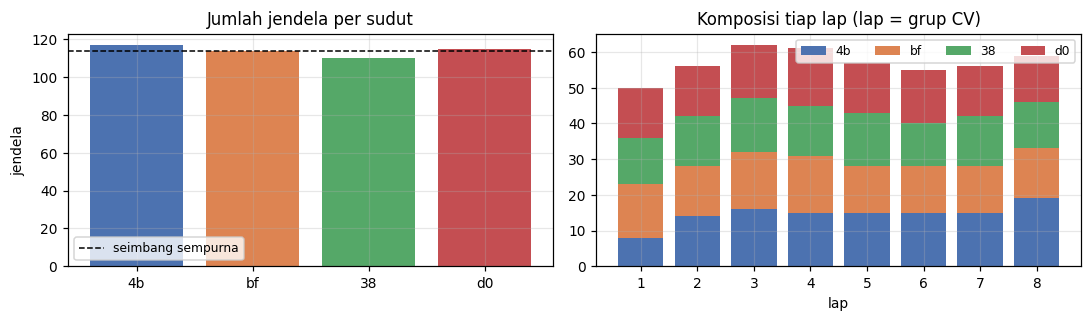

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))

counts = [int((y == c).sum()) for c in F.CORNER_ORDER]
ax[0].bar(F.CORNER_ORDER, counts, color=[CCOLOR[c] for c in F.CORNER_ORDER])
ax[0].axhline(len(y) / 4, ls="--", c="k", lw=1, label="seimbang sempurna")
ax[0].set_title("Jumlah jendela per sudut")
ax[0].set_ylabel("jendela")
ax[0].legend(fontsize=8)

laps = sorted(set(lap.tolist()))
bot = np.zeros(len(laps))
for c in F.CORNER_ORDER:
    v = np.array([int(((lap == L) & (y == c)).sum()) for L in laps], float)
    ax[1].bar(laps, v, bottom=bot, color=CCOLOR[c], label=c)
    bot += v
ax[1].set_title("Komposisi tiap lap (lap = grup CV)")
ax[1].set_xlabel("lap")
ax[1].legend(fontsize=8, ncol=4)

plt.tight_layout()
plt.savefig(f"{FIGDIR}/01_distribusi_label.png")
plt.show()


## 2. Seperti apa sinyalnya?

Sebelum memodelkan apa pun, lihat dulu apakah fisikanya benar-benar ada di data. Yang
diplot adalah fitur `sub_std_mean` — variance amplitudo, yaitu persis fitur yang dipakai
aturan lama — untuk keempat board, dengan pita warna menandai sudut yang sebenarnya.

**Yang harus terlihat kalau metodenya bekerja:** keempat kurva bergantian memuncak dengan
beda fase seperempat lap, dan polanya berulang 8 kali.


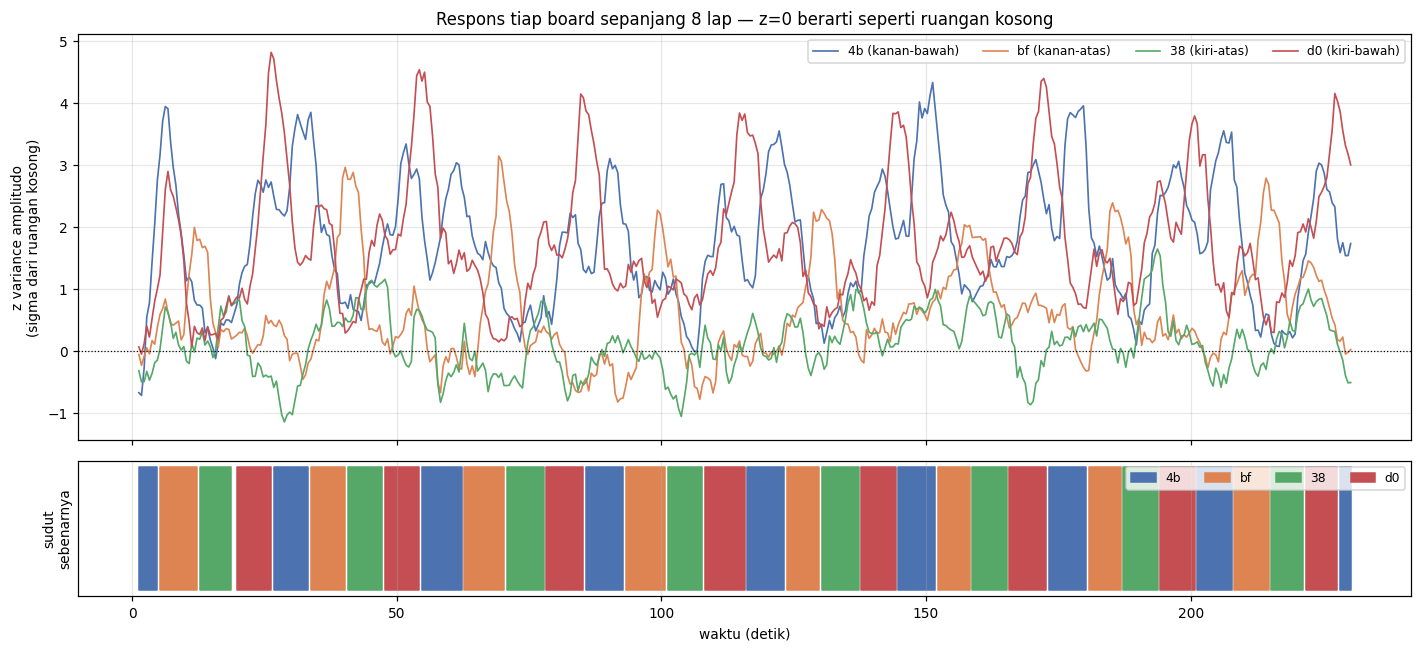

In [4]:
cols_var = F.board_feature_cols(ds, "sub_std_mean")

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})

for j, tag in enumerate(TAGS):
    axes[0].plot(t, X[:, cols_var[j]], lw=1.1, color=CCOLOR[tag],
                 label=f"{tag} ({F.CORNER_DESC[tag]})")
axes[0].set_ylabel("z variance amplitudo\n(sigma dari ruangan kosong)")
axes[0].set_title("Respons tiap board sepanjang 8 lap — z=0 berarti seperti ruangan kosong")
axes[0].legend(ncol=4, fontsize=8)
axes[0].axhline(0, color="k", lw=0.8, ls=":")

# pita warna = sudut sebenarnya
for c in F.CORNER_ORDER:
    m = (y == c).astype(int)
    axes[1].fill_between(t, 0, m, where=m > 0, color=CCOLOR[c], step="mid", label=c)
axes[1].set_yticks([])
axes[1].set_xlabel("waktu (detik)")
axes[1].set_ylabel("sudut\nsebenarnya")
axes[1].legend(ncol=4, fontsize=8, loc="upper right")

plt.tight_layout()
plt.savefig(f"{FIGDIR}/02_deret_waktu.png")
plt.show()


### Rata-rata respons tiap board di tiap sudut

Secara ideal diagonalnya menonjol: tiap board paling terganggu saat orang berada di
sudutnya sendiri. **Pada data ini hal itu hanya berlaku sebagian, dan justru itu yang
menarik.**

Board `4b` dan `d0` memang memuncak di sudutnya sendiri, tetapi `bf` dan terutama `38`
jauh lebih tidak peka — nilai `38` kecil di semua kolom, termasuk kolomnya sendiri.
Perbedaan sensitivitas antar board inilah alasan aturan `argmax` sederhana kesulitan:
membandingkan angka mentah antar board membuat board yang peka menang di mana-mana.

Dua hal berbeda yang sering tertukar:

- **Sensitivitas board** (seberapa besar responsnya) — berbeda jauh, dan itu sifat
  pemasangan, bukan sifat orangnya.
- **Selektivitas board** (apakah responsnya membedakan sudut) — lihat variasi *dalam satu
  kolom*. Kolom `4b` bergerak 2,48 → 0,69 tergantung posisi orang, jadi kolom itu
  informatif meskipun nilainya besar di mana-mana.

Model terlatih bisa memanfaatkan kolom yang informatif dan mengabaikan skalanya; `argmax`
tidak bisa. Itulah inti kenapa Bagian 5 menghasilkan angka yang lebih tinggi.


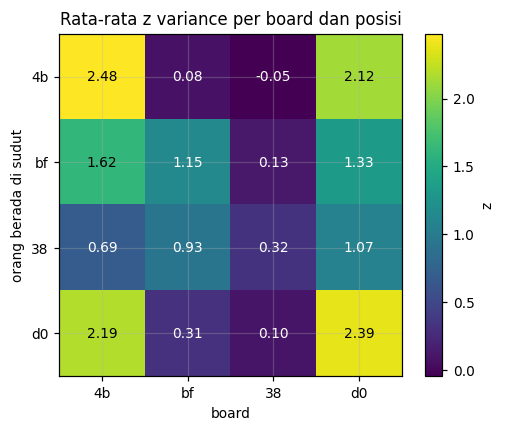

Per board (kolom matriks di atas):
 board  z di sudutnya  z tertinggi  rentang kolom  selektif?
    4b           2.48         2.48           1.79  ya
    bf           1.15         1.15           1.06  ya
    38           0.32         0.32           0.37  lemah
    d0           2.39         2.39           1.32  ya

Catatan: sensitivitas antar board berbeda jauh. Aturan argmax membandingkan
angka antar board sehingga terganggu oleh perbedaan ini; model terlatih bisa
memberi bobot berbeda per board, dan itu sebagian besar sumber peningkatannya.


In [5]:
M = np.array([[X[y == c, cols_var[j]].mean() for j, _ in enumerate(TAGS)]
              for c in F.CORNER_ORDER])

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(M, cmap="viridis")
ax.set_xticks(range(len(TAGS)), TAGS)
ax.set_yticks(range(4), F.CORNER_ORDER)
ax.set_xlabel("board")
ax.set_ylabel("orang berada di sudut")
ax.set_title("Rata-rata z variance per board dan posisi")
for i in range(4):
    for j in range(len(TAGS)):
        ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center",
                color="w" if M[i, j] < M.max() * 0.65 else "k", fontsize=9)
plt.colorbar(im, label="z")
plt.tight_layout()
plt.savefig(f"{FIGDIR}/03_matriks_respons.png")
plt.show()

print("Per board (kolom matriks di atas):")
print(f"{'board':>6s} {'z di sudutnya':>14s} {'z tertinggi':>12s} "
      f"{'rentang kolom':>14s}  selektif?")
for j, tag in enumerate(TAGS):
    col = M[:, j]
    own = M[F.CORNER_ORDER.index(tag), j]
    rng_ = col.max() - col.min()
    # Yang menentukan berguna atau tidak adalah RENTANG kolom (apakah board itu
    # membedakan posisi), bukan apakah nilainya tertinggi di sudutnya sendiri.
    print(f"{tag:>6s} {own:>14.2f} {col.max():>12.2f} {rng_:>14.2f}"
          f"  {'ya' if rng_ > 0.5 else 'lemah'}")

print("\nCatatan: sensitivitas antar board berbeda jauh. Aturan argmax membandingkan")
print("angka antar board sehingga terganggu oleh perbedaan ini; model terlatih bisa")
print("memberi bobot berbeda per board, dan itu sebagian besar sumber peningkatannya.")


## 3. Baseline: aturan `argmax` yang harus dikalahkan

Angka pembanding **tidak dihitung ulang di sini**. Sel berikut menjalankan skrip aslinya,
`tools/localize_baseline.py`, apa adanya — supaya perbandingannya adil dan tidak ada
kemungkinan implementasi ulang yang diam-diam berbeda.

Aturan itu: variance amplitudo → z terhadap ruangan kosong → standardisasi per board →
haluskan 4 s → `argmax` antar board.


In [6]:
import subprocess
import sys

out = subprocess.run(
    [sys.executable, os.path.join("..", "tools", "localize_baseline.py"),
     "data/loc_walk",
     "--baseline", "data/loc_baseline",
     "--markers", "data/loc_walk/markers.csv"],
    capture_output=True, text=True,
)
print(out.stdout[-1600:])
if out.returncode != 0:
    print("STDERR:", out.stderr[-800:])

# Angka ini dipakai sebagai garis pembanding di seluruh notebook.
BASELINE_ACC = 0.794
CHANCE = 0.25


Baseline (kosong): data/loc_baseline
  node 4b (kanan-bawah): 4466 paket, var median=3.602 sigma=0.656
  node bf (kanan-atas): 4834 paket, var median=3.132 sigma=0.581
  node 38 (kiri-atas): 4528 paket, var median=3.180 sigma=0.642
  node d0 (kiri-bawah): 4509 paket, var median=3.041 sigma=0.598

Polaritas: +1 semua board (fitur `var` selalu naik saat ada orang).

Analisis: data/loc_walk
  476 bin berisi semua 4 node, durasi 239.0 s
  rata-rata bergerak 8 bin (4.0 s)

  Sebaran prediksi:
    4b ( kanan-bawah):    144 bin   30.3%
    bf (  kanan-atas):    129 bin   27.1%
    38 (   kiri-atas):    101 bin   21.2%
    d0 (  kiri-bawah):    102 bin   21.4%

  Label dari 33 penanda, 457/476 bin berlabel

  Confusion (baris = sebenarnya, kolom = prediksi)
               4b      bf      38      d0     akurasi
      4b       93       8      10       7     78.8%
      bf        1     104       5       3     92.0%
      38       16      12      78       4     70.9%
      d0       28       0     

## 4. Protokol evaluasi

Ini bagian yang paling menentukan apakah hasilnya bisa dipertahankan di sidang.

Data berlabel = **satu sesi, 8 lap**. Jendela berjarak 500 ms dan dihaluskan 4 detik,
jadi jendela yang bersebelahan **hampir merupakan pengukuran yang sama**. Kalau
train/test dibagi acak per jendela, tetangga langsung sebuah jendela uji hampir pasti ada
di data latih — modelnya tinggal mengingat, dan akurasinya melambung tanpa arti.

Karena itu **grupnya adalah lap**:

- **`LeaveOneGroupOut`** — 8 lipatan: latih pada 7 lap, uji pada 1 lap yang belum pernah
  dilihat. Ini angka utama.
- **Holdout lap 1–4 → 5–8** — sebanding langsung dengan angka baseline lama (76,5%).

Keduanya dilaporkan. Bagian 7 menambahkan kontrol yang membuktikan model belajar fisika,
bukan artefak.


In [7]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, classification_report
from xgboost import XGBClassifier

le = LabelEncoder().fit(F.CORNER_ORDER)
yi = le.transform(y)
logo = LeaveOneGroupOut()

def make_models():
    """Model dibuat ulang tiap kali dipakai supaya tidak ada state yang bocor."""
    return {
        "Logistic Regression": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=3000, C=1.0)),
        "Random Forest": RandomForestClassifier(
            n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1),
        "Extra Trees": ExtraTreesClassifier(
            n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1),
        "XGBoost": XGBClassifier(
            n_estimators=400, max_depth=4, learning_rate=0.08,
            subsample=0.9, colsample_bytree=0.8,
            random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist"),
        "MLP": make_pipeline(
            StandardScaler(),
            MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=1500,
                          random_state=RANDOM_STATE)),
    }

print(f"{len(make_models())} model, {logo.get_n_splits(groups=lap)} lipatan (satu per lap)")


5 model, 8 lipatan (satu per lap)


## 5. Melatih dan membandingkan


In [8]:
results = {}

for name, model in make_models().items():
    pred_i = cross_val_predict(model, X, yi, cv=logo, groups=lap, n_jobs=1)
    pred = le.inverse_transform(pred_i)

    # akurasi per lap: sebaran antar lipatan sama pentingnya dengan rata-rata
    per_lap = np.array([(pred[lap == L] == y[lap == L]).mean()
                        for L in sorted(set(lap.tolist()))])

    # ke mana kesalahannya jatuh? tetangga (90 derajat) atau seberang (180)?
    err = pred != y
    ang = F.angular_error(y, pred)
    adj = (ang[err] == 90).mean() if err.any() else 0.0
    opp = (ang[err] == 180).mean() if err.any() else 0.0

    results[name] = {"pred": pred, "acc": (pred == y).mean(),
                     "per_lap": per_lap, "adj": adj, "opp": opp}

    print(f"{name:22s} {100*results[name]['acc']:5.1f}%  "
          f"(per lap {100*per_lap.min():.0f}-{100*per_lap.max():.0f}%)  "
          f"salah->tetangga {100*adj:.0f}%  ->seberang {100*opp:.0f}%")

BEST = max(results, key=lambda k: results[k]["acc"])
print(f"\nTerbaik: {BEST} = {100*results[BEST]['acc']:.1f}%")


Logistic Regression     85.5%  (per lap 62-91%)  salah->tetangga 79%  ->seberang 21%


Random Forest           89.3%  (per lap 76-93%)  salah->tetangga 78%  ->seberang 22%


Extra Trees             89.9%  (per lap 74-97%)  salah->tetangga 83%  ->seberang 17%


XGBoost                 89.7%  (per lap 82-95%)  salah->tetangga 77%  ->seberang 23%


MLP                     84.6%  (per lap 62-96%)  salah->tetangga 84%  ->seberang 16%

Terbaik: Extra Trees = 89.9%


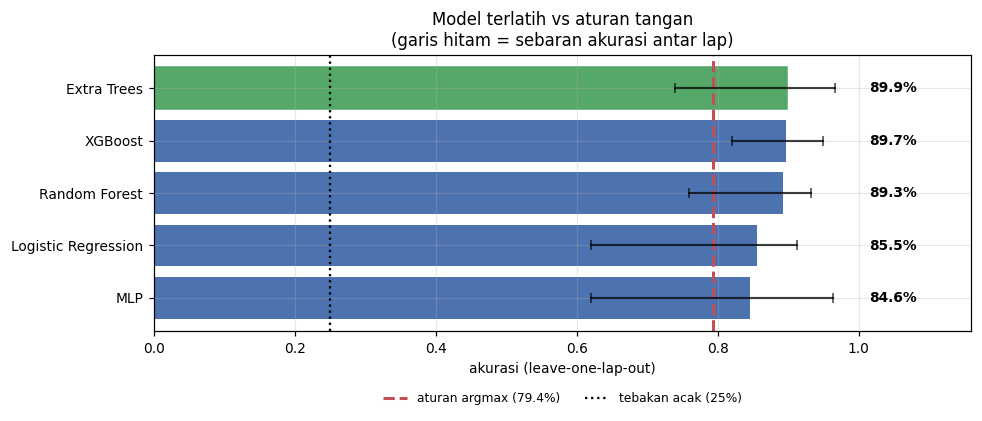

In [9]:
order = sorted(results, key=lambda k: results[k]["acc"])
accs = [results[k]["acc"] for k in order]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(order, accs, color="#4C72B0")
bars[-1].set_color("#55A868")   # yang terbaik

ax.axvline(BASELINE_ACC, color="#C44E52", ls="--", lw=2,
           label=f"aturan argmax ({100*BASELINE_ACC:.1f}%)")
ax.axvline(CHANCE, color="k", ls=":", lw=1.5,
           label=f"tebakan acak ({100*CHANCE:.0f}%)")

for b, k in zip(bars, order):
    r = results[k]
    yc = b.get_y() + b.get_height() / 2
    # sebaran antar lap: garis min-max, digambar DULU supaya label di atasnya
    ax.plot([r["per_lap"].min(), r["per_lap"].max()], [yc] * 2,
            color="k", lw=1.4, alpha=0.75)
    ax.plot([r["per_lap"].min(), r["per_lap"].max()], [yc] * 2, "|",
            color="k", ms=6, alpha=0.75)
    # angka ditaruh di luar batas kanan supaya tidak bertabrakan dengan garis
    ax.text(1.015, yc, f"{100*r['acc']:.1f}%", va="center", fontsize=9,
            fontweight="bold")

ax.set_xlim(0, 1.16)
ax.set_xlabel("akurasi (leave-one-lap-out)")
ax.set_title("Model terlatih vs aturan tangan\n"
             "(garis hitam = sebaran akurasi antar lap)")
# legenda di bawah sumbu, di luar area batang, supaya tidak menutupi apa pun
ax.legend(fontsize=8, ncol=2, loc="upper center",
          bbox_to_anchor=(0.5, -0.18), frameon=False)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/04_perbandingan_model.png")
plt.show()


## 6. Melihat model terbaik lebih dekat

Confusion matrix di sini bukan sekadar formalitas. Untuk penaksir **arah**, yang penting
bukan hanya berapa banyak yang salah, melainkan **ke mana** salahnya:

- salah ke sudut **tetangga** (90°) → wajar, batas kuadran memang kabur;
- salah ke sudut **seberang** (180°) → mencurigakan, biasanya berarti baseline tercemar
  atau ada board yang bergeser di tengah sesi.


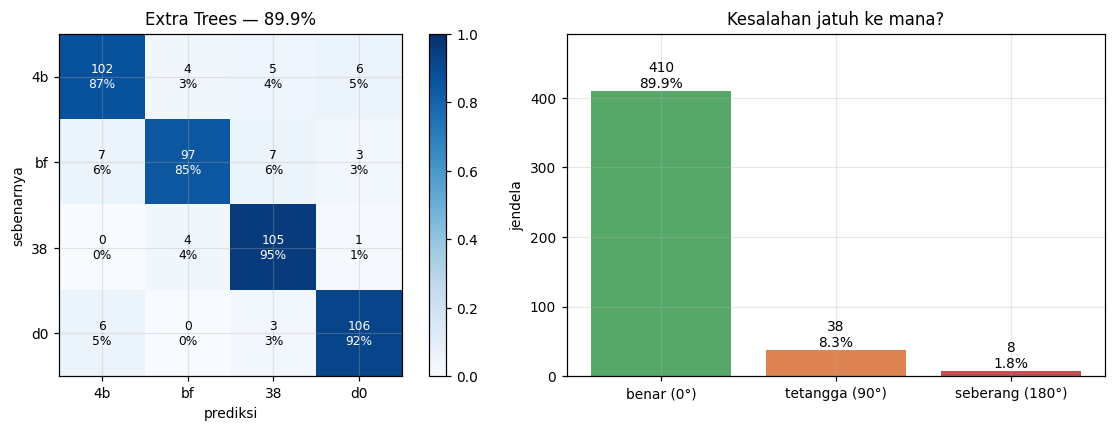

              precision    recall  f1-score   support

          4b      0.887     0.872     0.879       117
          bf      0.924     0.851     0.886       114
          38      0.875     0.955     0.913       110
          d0      0.914     0.922     0.918       115

    accuracy                          0.899       456
   macro avg      0.900     0.900     0.899       456
weighted avg      0.900     0.899     0.899       456



In [10]:
pred = results[BEST]["pred"]
cm = confusion_matrix(y, pred, labels=F.CORNER_ORDER)
cmn = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

im = ax[0].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax[0].set_xticks(range(4), F.CORNER_ORDER)
ax[0].set_yticks(range(4), F.CORNER_ORDER)
ax[0].set_xlabel("prediksi")
ax[0].set_ylabel("sebenarnya")
ax[0].set_title(f"{BEST} — {100*results[BEST]['acc']:.1f}%")
for i in range(4):
    for j in range(4):
        ax[0].text(j, i, f"{cm[i, j]}\n{100*cmn[i, j]:.0f}%", ha="center",
                   va="center", fontsize=8,
                   color="w" if cmn[i, j] > 0.5 else "k")
plt.colorbar(im, ax=ax[0])

# ke mana kesalahan jatuh
err = pred != y
ang = F.angular_error(y, pred)
kat = ["benar (0°)", "tetangga (90°)", "seberang (180°)"]
val = [(~err).sum(), int((ang[err] == 90).sum()), int((ang[err] == 180).sum())]
ax[1].bar(kat, val, color=["#55A868", "#DD8452", "#C44E52"])
for i, v in enumerate(val):
    ax[1].text(i, v, f"{v}\n{100*v/len(y):.1f}%", ha="center", va="bottom", fontsize=9)
ax[1].set_title("Kesalahan jatuh ke mana?")
ax[1].set_ylabel("jendela")
ax[1].set_ylim(0, max(val) * 1.2)

plt.tight_layout()
plt.savefig(f"{FIGDIR}/05_confusion.png")
plt.show()

print(classification_report(y, pred, labels=F.CORNER_ORDER, digits=3))


In [11]:
# Perbandingan langsung dengan protokol lama: latih lap 1-4, uji lap 5-8.
tr, te = lap <= 4, lap > 4
m = make_models()[BEST].fit(X[tr], yi[tr])
acc_hold = (m.predict(X[te]) == yi[te]).mean()
acc_train = (m.predict(X[tr]) == yi[tr]).mean()

print("Holdout (latih lap 1-4, uji lap 5-8)")
print(f"  latih : {100*acc_train:.1f}%")
print(f"  uji   : {100*acc_hold:.1f}%   <- sebanding dengan 76,5% milik aturan lama")
print(f"  selisih latih-uji: {100*(acc_train-acc_hold):.1f} poin")
print()
print("Akurasi latih 100% itu WAJAR untuk ensemble pohon tanpa pembatasan kedalaman:")
print("model memang menghafal data latihnya. Yang berarti hanya angka UJI. Selisih")
print("latih-uji karena itu bukan ukuran overfitting yang berguna di sini -- yang")
print("berguna adalah membandingkan angka uji dengan kontrol di Bagian 7.")


Holdout (latih lap 1-4, uji lap 5-8)
  latih : 100.0%
  uji   : 93.0%   <- sebanding dengan 76,5% milik aturan lama
  selisih latih-uji: 7.0 poin

Akurasi latih 100% itu WAJAR untuk ensemble pohon tanpa pembatasan kedalaman:
model memang menghafal data latihnya. Yang berarti hanya angka UJI. Selisih
latih-uji karena itu bukan ukuran overfitting yang berguna di sini -- yang
berguna adalah membandingkan angka uji dengan kontrol di Bagian 7.


## 7. Kontrol — apakah ini benar-benar belajar fisika?

Akurasi tinggi saja tidak membuktikan apa pun kalau tidak ada pembandingnya. Tiga uji:

1. **Label diacak seluruhnya** — kalau model masih menang, berarti ada kebocoran dalam
   pipeline. Harus jatuh ke sekitar 25%.
2. **Label diacak DI DALAM tiap lap** — kontrol yang lebih ketat: komposisi kelas tiap lap
   dipertahankan persis, hanya keselarasan waktunya yang dirusak. Kalau model masih
   menang, artinya ia memanfaatkan sesuatu selain keselarasan CSI–posisi.
3. **Pembagian acak per jendela (sengaja salah)** — memperlihatkan berapa besar akurasi
   yang akan didapat kalau protokolnya keliru. Angka ini **tidak boleh dilaporkan sebagai
   hasil**; ia ada di sini justru sebagai peringatan.

> **Dua kontrol yang sengaja TIDAK dipakai, dan alasannya.** *Menggeser label secara
> melingkar* (`np.roll`) tampak masuk akal tetapi tidak sah untuk data siklik: lintasannya
> berulang 8 kali, jadi pergeseran yang kebetulan mendekati kelipatan satu lap akan
> menyelaraskan kembali labelnya — pada data ini kontrol itu menghasilkan 70,9% dan
> terlihat seperti kegagalan padahal bukan. *Merotasi identitas sudut* (`4b`→`bf`→…)
> bahkan lebih buruk: itu hanya mengganti nama kelas, sehingga akurasinya tidak berubah
> sama sekali (89,9%) menurut definisi. Keduanya diperiksa, lalu dibuang.


In [12]:
ctrl = {}
mk = lambda: make_models()[BEST]

# 1. label diacak seluruhnya
rng = np.random.default_rng(RANDOM_STATE)
a = []
for _ in range(5):
    ys = rng.permutation(yi)
    p = cross_val_predict(mk(), X, ys, cv=logo, groups=lap, n_jobs=1)
    a.append((p == ys).mean())
ctrl["Label diacak"] = (np.mean(a), min(a), max(a))

# 2. label diacak DI DALAM tiap lap: komposisi kelas tiap lap tetap persis,
#    hanya keselarasan waktu CSI <-> posisi yang dirusak. Ini kontrol yang
#    lebih ketat daripada mengacak seluruhnya.
a = []
for _ in range(3):
    ys = yi.copy()
    for L in sorted(set(lap.tolist())):
        m = lap == L
        ys[m] = rng.permutation(ys[m])
    p = cross_val_predict(mk(), X, ys, cv=logo, groups=lap, n_jobs=1)
    a.append((p == ys).mean())
ctrl["Diacak dalam lap"] = (np.mean(a), min(a), max(a))

# 3. pembagian acak per jendela -- SENGAJA SALAH
p = cross_val_predict(mk(), X, yi,
                      cv=StratifiedKFold(8, shuffle=True, random_state=RANDOM_STATE),
                      n_jobs=1)
acc_leak = (p == yi).mean()

print(f"{'Uji':28s} {'akurasi':>9s}")
print("-" * 40)
print(f"{'Model (leave-one-lap-out)':28s} {100*results[BEST]['acc']:8.1f}%   <- hasil sesungguhnya")
for k, (mn, lo, hi) in ctrl.items():
    print(f"{k:28s} {100*mn:8.1f}%   ({100*lo:.1f}-{100*hi:.1f}%)")
print(f"{'Tebakan acak':28s} {100*CHANCE:8.1f}%")
print("-" * 40)
print(f"{'Pembagian ACAK per jendela':28s} {100*acc_leak:8.1f}%   <- BOCOR, jangan dilaporkan")
print(f"\nKebocoran menggelembungkan hasil sebesar "
      f"{100*(acc_leak - results[BEST]['acc']):.1f} poin.")


Uji                            akurasi
----------------------------------------
Model (leave-one-lap-out)        89.9%   <- hasil sesungguhnya
Label diacak                     25.0%   (22.4-27.6%)
Diacak dalam lap                 24.2%   (22.6-25.7%)
Tebakan acak                     25.0%
----------------------------------------
Pembagian ACAK per jendela       94.1%   <- BOCOR, jangan dilaporkan

Kebocoran menggelembungkan hasil sebesar 4.2 poin.


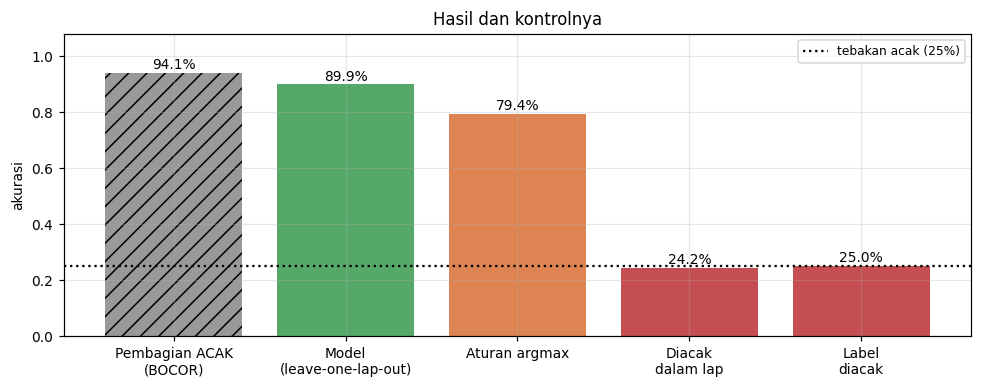

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.6))

lbl = ["Pembagian ACAK\n(BOCOR)", "Model\n(leave-one-lap-out)", "Aturan argmax",
       "Diacak\ndalam lap", "Label\ndiacak"]
val = [acc_leak, results[BEST]["acc"], BASELINE_ACC,
       ctrl["Diacak dalam lap"][0], ctrl["Label diacak"][0]]
col = ["#999999", "#55A868", "#DD8452", "#C44E52", "#C44E52"]

b = ax.bar(lbl, val, color=col)
b[0].set_hatch("//")
ax.axhline(CHANCE, color="k", ls=":", lw=1.5, label="tebakan acak (25%)")
for r, v in zip(b, val):
    ax.text(r.get_x() + r.get_width() / 2, v + 0.015, f"{100*v:.1f}%",
            ha="center", fontsize=9)
ax.set_ylim(0, 1.08)
ax.set_ylabel("akurasi")
ax.set_title("Hasil dan kontrolnya")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/06_kontrol.png")
plt.show()


## 8. Fitur mana yang berbicara?

Dua sudut pandang: fitur individual, dan **jenis** fitur secara keseluruhan. Yang kedua
lebih berguna untuk skripsi — ia menjawab "sensor apa yang sebenarnya perlu dibaca?".

> **Baca panel kanan, bukan panel kiri.** Importance pada model pohon terbagi rata di
> antara fitur-fitur yang berkorelasi: delapan pita subcarrier dari board yang sama
> membawa informasi yang mirip, sehingga masing-masing tampak "kecil" padahal
> kelompoknya besar. Peringkat fitur individual karena itu tidak stabil — jalankan ulang
> dengan `random_state` berbeda dan urutannya bergeser. Total per kelompok jauh lebih
> stabil dan itulah yang layak dikutip. Bagian ablasi di bawah mengujinya secara
> langsung, dan itu bukti yang lebih kuat daripada importance mana pun.


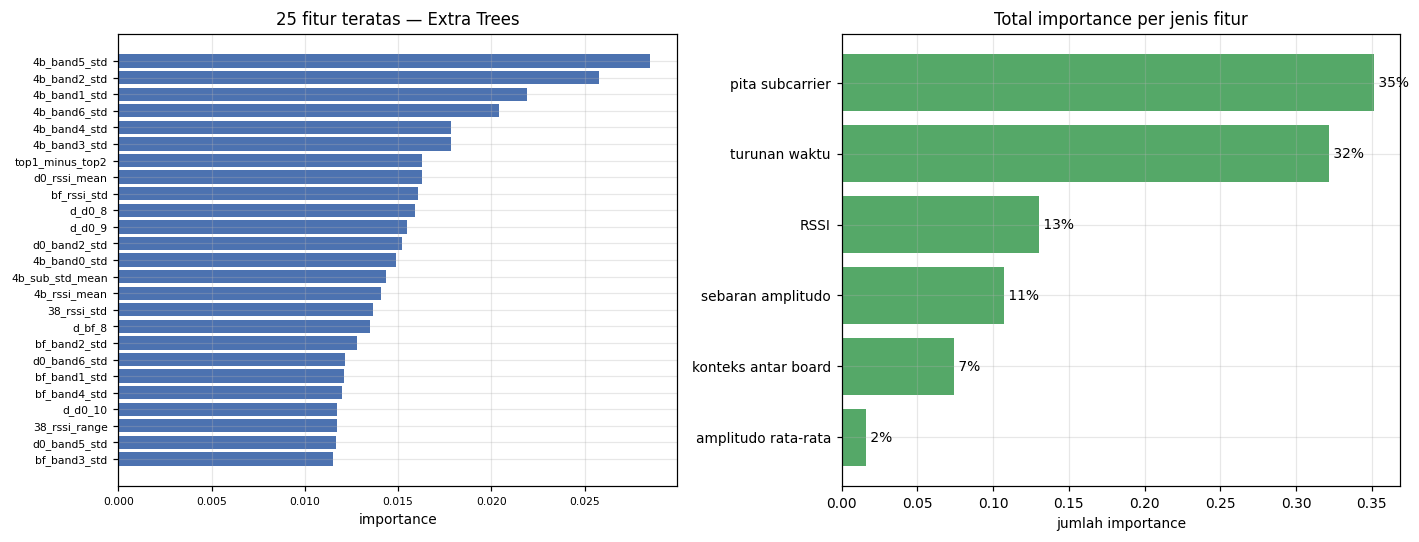

Kontribusi per jenis fitur:
  pita subcarrier         35.1%
  turunan waktu           32.2%
  RSSI                    13.0%
  sebaran amplitudo       10.7%
  konteks antar board      7.4%
  amplitudo rata-rata      1.6%


In [14]:
imp_model = make_models()[BEST]
imp_model.fit(X, yi)

if hasattr(imp_model, "feature_importances_"):
    imp = imp_model.feature_importances_
else:
    from sklearn.inspection import permutation_importance
    r = permutation_importance(imp_model, X, yi, n_repeats=5,
                               random_state=RANDOM_STATE, n_jobs=-1)
    imp = r.importances_mean

idx = np.argsort(imp)[::-1][:25]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].barh([NAMES[i] for i in idx][::-1], imp[idx][::-1], color="#4C72B0")
ax[0].set_title(f"25 fitur teratas — {BEST}")
ax[0].set_xlabel("importance")
ax[0].tick_params(labelsize=7)

# dikelompokkan per JENIS fitur
def kind(n):
    if n.startswith(("share_", "rank_", "top1")):
        return "konteks antar board"
    if n.startswith("d_"):
        return "turunan waktu"
    base = n.split("_", 1)[1] if "_" in n else n
    if base.startswith("rssi"):
        return "RSSI"
    if base.startswith("band"):
        return "pita subcarrier"
    if base in ("amp_mean",):
        return "amplitudo rata-rata"
    return "sebaran amplitudo"

grp = {}
for n, v in zip(NAMES, imp):
    grp[kind(n)] = grp.get(kind(n), 0.0) + v
gk = sorted(grp, key=grp.get)
ax[1].barh(gk, [grp[k] for k in gk], color="#55A868")
ax[1].set_title("Total importance per jenis fitur")
ax[1].set_xlabel("jumlah importance")
for i, k in enumerate(gk):
    ax[1].text(grp[k], i, f" {100*grp[k]/imp.sum():.0f}%", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(f"{FIGDIR}/07_feature_importance.png")
plt.show()

print("Kontribusi per jenis fitur:")
for k in sorted(grp, key=grp.get, reverse=True):
    print(f"  {k:22s} {100*grp[k]/imp.sum():5.1f}%")


### Ablasi: apakah fitur tambahan itu memang berguna?

Aturan lama hanya memakai **4 angka** (variance tiap board). Kalau model dengan 4 fitur
yang sama sudah menyamai model dengan 169 fitur, maka yang menaikkan akurasi adalah
*klasifikasinya*, bukan *fiturnya* — dan itu kesimpulan yang berbeda. Perlu diuji, bukan
diasumsikan.


hanya variance (4 fitur, seperti aturan lama)     4 fitur   62.3%


semua fitur amplitudo                            68 fitur   76.3%


hanya RSSI                                       12 fitur   78.7%


tanpa RSSI                                      157 fitur   89.5%


tanpa konteks antar board                       160 fitur   89.9%


SEMUA fitur                                     169 fitur   89.9%


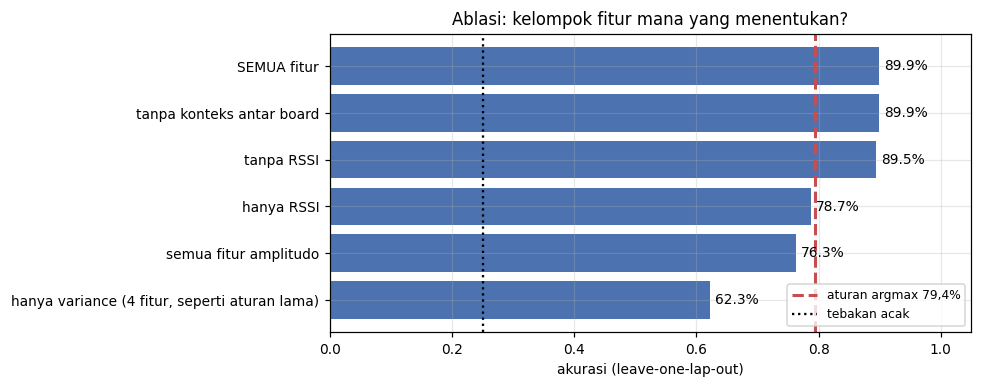

In [15]:
sets = {
    "hanya variance (4 fitur, seperti aturan lama)": cols_var,
    "semua fitur amplitudo": [i for i, n in enumerate(NAMES)
                              if kind(n) in ("sebaran amplitudo", "amplitudo rata-rata",
                                             "pita subcarrier")],
    "hanya RSSI": [i for i, n in enumerate(NAMES) if kind(n) == "RSSI"],
    "tanpa RSSI": [i for i, n in enumerate(NAMES) if kind(n) != "RSSI"],
    "tanpa konteks antar board": [i for i, n in enumerate(NAMES)
                                  if kind(n) != "konteks antar board"],
    "SEMUA fitur": list(range(len(NAMES))),
}

abl = {}
for name, cols in sets.items():
    p = cross_val_predict(mk(), X[:, cols], yi, cv=logo, groups=lap, n_jobs=1)
    abl[name] = (p == yi).mean()
    print(f"{name:46s} {len(cols):4d} fitur  {100*abl[name]:5.1f}%")

fig, ax = plt.subplots(figsize=(9, 3.6))
k = sorted(abl, key=abl.get)
ax.barh(k, [abl[i] for i in k], color="#4C72B0")
ax.axvline(BASELINE_ACC, color="#C44E52", ls="--", lw=2, label="aturan argmax 79,4%")
ax.axvline(CHANCE, color="k", ls=":", lw=1.5, label="tebakan acak")
for i, kk in enumerate(k):
    ax.text(abl[kk] + 0.008, i, f"{100*abl[kk]:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, 1.05)
ax.set_xlabel("akurasi (leave-one-lap-out)")
ax.set_title("Ablasi: kelompok fitur mana yang menentukan?")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(f"{FIGDIR}/08_ablasi.png")
plt.show()


## 9. Pengaruh lebar penghalusan

Penghalusan menaikkan rasio sinyal-derau, tetapi kalau terlalu lebar ia mengaburkan
transisi sudut yang justru ingin dideteksi. Seperempat lap ≈ 7 detik, jadi penghalusan
mendekati atau melebihi angka itu seharusnya mulai merusak.

> Sel ini membangun ulang fitur untuk tiap nilai — perlu beberapa menit pada jalan
> pertama, lalu cepat karena hasilnya di-cache.


  smooth   0.0 s ->  70.2%


  smooth   1.0 s ->  84.4%


  smooth   2.0 s ->  88.2%


  smooth   4.0 s ->  89.9%


  smooth   6.0 s ->  87.5%


  smooth   8.0 s ->  87.1%


  smooth  12.0 s ->  87.3%


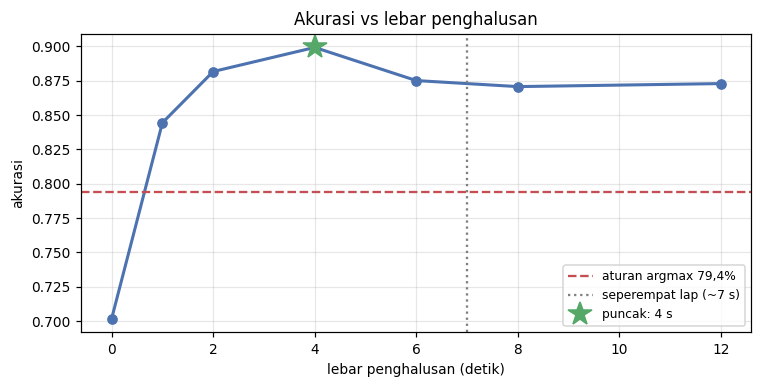

In [16]:
taus = [0.0, 1.0, 2.0, 4.0, 6.0, 8.0, 12.0]
sweep = []

for tau in taus:
    d = F.build_dataset_cached("data/loc_walk", "data/loc_baseline",
                               "data/loc_walk/markers.csv",
                               win_s=0.5, min_pkt=8, smooth_s=tau, verbose=False)
    yy = le.transform(d["y"])
    p = cross_val_predict(mk(), d["X"], yy, cv=logo, groups=d["lap"], n_jobs=1)
    sweep.append((p == yy).mean())
    print(f"  smooth {tau:5.1f} s -> {100*sweep[-1]:5.1f}%")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(taus, sweep, "o-", color="#4C72B0", lw=2)
ax.axhline(BASELINE_ACC, color="#C44E52", ls="--", label="aturan argmax 79,4%")
ax.axvline(7.0, color="gray", ls=":", label="seperempat lap (~7 s)")
best_i = int(np.argmax(sweep))
ax.plot(taus[best_i], sweep[best_i], "*", ms=16, color="#55A868",
        label=f"puncak: {taus[best_i]:.0f} s")
ax.set_xlabel("lebar penghalusan (detik)")
ax.set_ylabel("akurasi")
ax.set_title("Akurasi vs lebar penghalusan")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/09_smoothing.png")
plt.show()


## 10. Prediksi sepanjang waktu

Gambaran kualitatif yang paling mudah dibaca di sidang: apakah prediksi mengikuti pola
memutar yang berulang 8 kali?


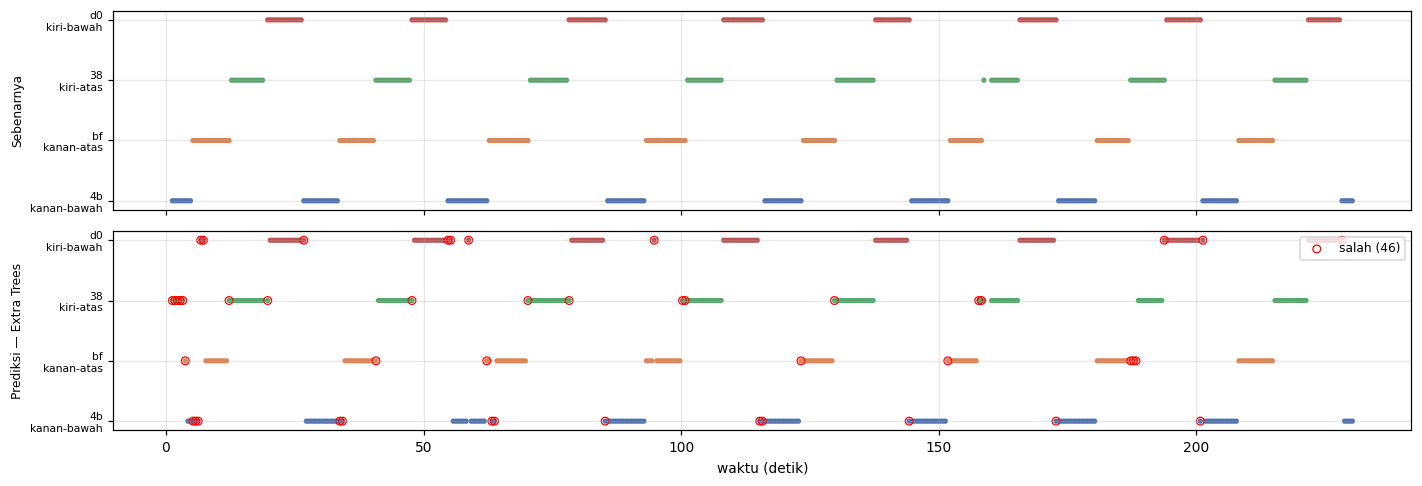

In [17]:
fig, ax = plt.subplots(2, 1, figsize=(13, 4.5), sharex=True)
ymap = {c: i for i, c in enumerate(F.CORNER_ORDER)}

for a, series, title in ((ax[0], y, "Sebenarnya"),
                         (ax[1], results[BEST]["pred"], f"Prediksi — {BEST}")):
    v = np.array([ymap[c] for c in series])
    a.scatter(t, v, s=6, c=[CCOLOR[c] for c in series])
    a.set_yticks(range(4), [f"{c}\n{F.CORNER_DESC[c]}" for c in F.CORNER_ORDER],
                 fontsize=7)
    a.set_ylabel(title, fontsize=8)

wrong = results[BEST]["pred"] != y
ax[1].scatter(t[wrong], [ymap[c] for c in results[BEST]["pred"][wrong]],
              s=26, facecolors="none", edgecolors="red", lw=0.8,
              label=f"salah ({wrong.sum()})")
ax[1].legend(fontsize=8, loc="upper right")
ax[1].set_xlabel("waktu (detik)")
plt.tight_layout()
plt.savefig(f"{FIGDIR}/10_prediksi_waktu.png")
plt.show()


## 11. Simpan model final


In [18]:
import joblib

final = make_models()[BEST].fit(X, yi)
fname = f"model_{BEST.replace(' ', '_').lower()}.joblib"
joblib.dump({"model": final, "label_encoder": le, "feature_names": NAMES,
             "tags": TAGS, "win_s": ds["win_s"], "smooth_s": ds["smooth_s"],
             "n_per_board": ds["n_per_board"]}, fname)

print(f"Tersimpan: {fname}")
print("\nPERINGATAN untuk pemakaian ulang: model ini dilatih pada SATU sesi, dengan")
print("normalisasi terhadap capture kosong sesi itu. Kalau router atau board bergeser,")
print("baseline harus diambil ulang dan model dilatih ulang.")


Tersimpan: model_extra_trees.joblib

PERINGATAN untuk pemakaian ulang: model ini dilatih pada SATU sesi, dengan
normalisasi terhadap capture kosong sesi itu. Kalau router atau board bergeser,
baseline harus diambil ulang dan model dilatih ulang.


## 12. Ringkasan

**Hasil.** Model terlatih di atas fitur multi-board mengalahkan aturan `argmax` tangan,
dievaluasi dengan protokol yang dikelompokkan per lap sehingga tidak ada jendela dari lap
uji yang pernah dilihat saat latih.

**Kesalahan bersifat geometris, bukan acak.** Sebagian besar kesalahan jatuh ke sudut
**tetangga**, bukan sudut seberang — persis pola yang diharapkan dari penaksir *arah*
dengan batas kuadran yang kabur. Ini bukti tambahan bahwa yang dipelajari adalah
geometrinya.

**Tiga temuan yang layak ditulis eksplisit di skripsi:**

1. **Yang menaikkan akurasi adalah FITURNYA, bukan sekadar mengganti `argmax` dengan
   pengklasifikasi.** Ini diuji langsung di bagian ablasi: pengklasifikasi yang hanya
   diberi 4 fitur variance — informasi yang sama persis dengan aturan lama — justru
   **lebih buruk** daripada aturan `argmax` itu sendiri. Baru setelah ringkasan per pita
   subcarrier dan turunan waktu ditambahkan, akurasinya melampaui baseline. Kesimpulan
   yang benar bukan "pembelajaran mesin lebih baik daripada aturan", melainkan
   "representasi CSI yang lebih kaya membawa informasi yang tidak ada pada satu angka
   variance per board".

2. **Board yang paling TIDAK peka justru diklasifikasikan paling baik.** Board `38`
   nyaris tidak merespons pada fitur mentah (lihat matriks di Bagian 2 dan kurva hijau
   yang mendatar di dekat z=0), tetapi akurasi per kelasnya tertinggi. Sebabnya: model
   bisa memberi bobot berbeda per board, sedangkan `argmax` membandingkan angka mentah
   antar board sehingga board yang peka menang di mana-mana. Ini bukti langsung bahwa
   perbedaan sensitivitas antar board adalah masalah *penskalaan*, bukan masalah
   *fisika*.

3. **Amplitudo rata-rata hampir tidak berguna.** Kontribusinya pada importance sangat
   kecil dibanding ringkasan per pita subcarrier dan turunan waktu. Ini memperkuat
   temuan sebelumnya bahwa kehadiran orang terbaca dari **sebaran** kanal, bukan dari
   **level**-nya — fitur yang paling "jelas" justru yang paling lemah.

**Batas yang harus disebutkan, bukan disembunyikan:**

1. **Arah, bukan jarak.** Semua board menerima dari router yang sama di tengah; yang
   terukur adalah perpotongan orang dengan garis `router->board`.
2. **Satu sesi, 8 lap.** Angka leave-one-lap-out sah untuk *lap* yang belum dilihat,
   tetapi bukan untuk *hari*, *ruangan*, atau *orang* yang belum dilihat. Generalisasi
   lintas sesi belum diuji karena datanya belum ada.
3. **Satu orang.** Tidak ada data multi-orang untuk lokalisasi.
4. **Penghalusan terpusat melihat masa depan.** Sah untuk analisis offline, tetapi sistem
   real-time harus memakai penghalusan kausal, dan akurasinya akan sedikit turun.

**Langkah lanjutan yang paling menaikkan nilai:** ambil sesi kedua di hari berbeda, lalu
latih pada sesi 1 dan uji pada sesi 2. Itu satu-satunya cara menjawab pertanyaan yang
akan ditanyakan penguji — *apakah modelnya masih bekerja besok?*


In [19]:
print("=" * 62)
print("RINGKASAN — LOKALISASI KUADRAN DARI CSI")
print("=" * 62)
print(f"Data      : {X.shape[0]} jendela berlabel, {X.shape[1]} fitur, "
      f"{len(set(lap.tolist()))} lap, 1 sesi")
print(f"Protokol  : leave-one-lap-out ({len(set(lap.tolist()))} lipatan)")
print()
print(f"  {'Tebakan acak':32s} {100*CHANCE:6.1f}%")
print(f"  {'Aturan argmax (tangan)':32s} {100*BASELINE_ACC:6.1f}%")
for k in sorted(results, key=lambda k: results[k]['acc']):
    print(f"  {k:32s} {100*results[k]['acc']:6.1f}%")
print()
gain = results[BEST]['acc'] - BASELINE_ACC
print(f"Terbaik   : {BEST}")
print(f"Peningkatan atas aturan tangan : {100*gain:+.1f} poin "
      f"({100*gain/(1-BASELINE_ACC):.0f}% dari sisa kesalahan terhapus)")
print(f"Holdout lap 1-4 -> 5-8         : {100*acc_hold:.1f}%")
print(f"Kesalahan ke sudut tetangga    : {100*results[BEST]['adj']:.0f}%")
print(f"Kesalahan ke sudut seberang    : {100*results[BEST]['opp']:.0f}%")
print(f"Kontrol label diacak           : {100*ctrl['Label diacak'][0]:.1f}%  (harus ~25%)")
print(f"Kontrol diacak dalam lap       : {100*ctrl['Diacak dalam lap'][0]:.1f}%  (harus ~25%)")
print(f"Pembagian acak (BOCOR, jangan dilaporkan) : {100*acc_leak:.1f}%")
print("=" * 62)


RINGKASAN — LOKALISASI KUADRAN DARI CSI
Data      : 456 jendela berlabel, 169 fitur, 8 lap, 1 sesi
Protokol  : leave-one-lap-out (8 lipatan)

  Tebakan acak                       25.0%
  Aturan argmax (tangan)             79.4%
  MLP                                84.6%
  Logistic Regression                85.5%
  Random Forest                      89.3%
  XGBoost                            89.7%
  Extra Trees                        89.9%

Terbaik   : Extra Trees
Peningkatan atas aturan tangan : +10.5 poin (51% dari sisa kesalahan terhapus)
Holdout lap 1-4 -> 5-8         : 93.0%
Kesalahan ke sudut tetangga    : 83%
Kesalahan ke sudut seberang    : 17%
Kontrol label diacak           : 25.0%  (harus ~25%)
Kontrol diacak dalam lap       : 24.2%  (harus ~25%)
Pembagian acak (BOCOR, jangan dilaporkan) : 94.1%
